In [3]:
#IMPORTING THE LIBRARIES
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
db_path = '/content/drive/MyDrive/Colab Notebooks/capstone_projects/classification.db'

In [4]:
#CONNECTING TO THE SQL LITE DATABASE
conn = sqlite3.connect(db_path)

In [5]:
cursor = conn.cursor()

In [6]:
# Query to retrieve table names
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")


In [7]:
# Fetch all table names
tables = cursor.fetchall()

In [8]:
# Print the table names
for table in tables:
    print(table[0])


fraud_detection
Heart_disease
Metro_Train_Maintenance
forest_cov_type
fake_news_classification
drug_reviews_sentiment_analysis
Telecom_microservices_loan
malware_detection
fault_detection_manufacturing


In [9]:
#CHECKING THE RECORDS IN FRAUD DETECTION TABLE
df = pd.read_sql_query('Select * from fraud_detection' , conn)


In [10]:
#UNDERSTANDING THE DATA
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [12]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.095390e+06,6.159017e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.550005e+05,1.101147e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.923541e+06,3.408166e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327682e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442704e+05,9.431247e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [13]:
# CHECKING THE MISSING VALUES
df.isnull().sum()

,0
step,0
type,203603
amount,0
nameOrig,203603
oldbalanceOrg,0
newbalanceOrig,267230
nameDest,0
oldbalanceDest,203603
newbalanceDest,0
isFraud,0


In [14]:
print(df["type"].value_counts(dropna=False))

type
CASH_OUT    2165868
PAYMENT     2082597
CASH_IN     1354742
TRANSFER     515688
None         203603
DEBIT         40122
Name: count, dtype: int64


In [15]:
#Understand the target variable
df['isFraud'].value_counts()

,count
isFraud,
0,6354407
1,8213


In [16]:
# SEE IN TERMS OF %
print(df["isFraud"].value_counts(normalize=True) * 100)

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


In [17]:
df['type'].value_counts()

,count
type,
CASH_OUT,2165868
PAYMENT,2082597
CASH_IN,1354742
TRANSFER,515688
DEBIT,40122


In [18]:
#Check fraud count by type:
print(pd.crosstab(df["type"], df["isFraud"]))

isFraud         0     1
type                   
CASH_IN   1354742     0
CASH_OUT  2161877  3991
DEBIT       40122     0
PAYMENT   2082597     0
TRANSFER   511757  3931


In [19]:
#Check fraud percentage by type:
#This gives us useful EDA information about which transaction types are associated with fraud.
print(df.groupby("type")["isFraud"].mean() * 100)

type
CASH_IN     0.000000
CASH_OUT    0.184268
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.762283
Name: isFraud, dtype: float64


In [20]:
#Identify categorical and numerical columns
cat_col = [col for col in df.columns if df[col].dtype == "object"]
num_col = [col for col in df.columns if df[col].dtype != "object"]

print("Categorical:", cat_col)
print("Numerical:", num_col)

Categorical: ['type', 'nameOrig', 'nameDest']
Numerical: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [21]:
#Dropping features which are not required
df.drop(['nameOrig' , 'nameDest','isFlaggedFraud'] , axis = 1 , inplace = True)

In [22]:
df.isnull().sum()

,0
step,0
type,203603
amount,0
oldbalanceOrg,0
newbalanceOrig,267230
oldbalanceDest,203603
newbalanceDest,0
isFraud,0


In [23]:
#Since type is the catagorical feature we cant use median so we are creating a new catagory called as missing
df["type"] = df["type"].fillna("MISSING")

In [24]:
df.isnull().sum()

,0
step,0
type,0
amount,0
oldbalanceOrg,0
newbalanceOrig,267230
oldbalanceDest,203603
newbalanceDest,0
isFraud,0


In [25]:
df['type'].value_counts()

,count
type,
CASH_OUT,2165868
PAYMENT,2082597
CASH_IN,1354742
TRANSFER,515688
MISSING,203603
DEBIT,40122


In [26]:
#Feature selection
features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

target = "isFraud"

In [27]:
#Create the working dataset
data = df[features + [target]].copy()

In [28]:
print(data.shape)
print(data.head())

(6362620, 8)
   step      type    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   PAYMENT   9839.64       170136.0       160296.36             0.0   
1     1   PAYMENT   1864.28        21249.0        19384.72             0.0   
2     1  TRANSFER    181.00          181.0            0.00             0.0   
3     1  CASH_OUT    181.00          181.0            0.00         21182.0   
4     1   PAYMENT  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  isFraud  
0             0.0        0  
1             0.0        0  
2             0.0        1  
3             0.0        1  
4             0.0        0  


In [29]:
data.head()


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,1
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0


In [30]:
#Find numerical missing values for newbalanceOrig oldbalanceDest
#First, determine the median from the first 4 million training records.Because those are your training records.
"""
Dataset	Records	Purpose
Training	First 4,000,000	Train the model -- Train data
Evaluation	Next 1,000,000	Test model performance -- Test data
Live	Remaining 1,362,620	Simulate future predictions -- Test data
"""

median_newbalanceOrig = data.iloc[:4_000_000]["newbalanceOrig"].median()

median_oldbalanceDest = data.iloc[:4_000_000]["oldbalanceDest"].median()

print("Median newbalanceOrig:", median_newbalanceOrig)
print("Median oldbalanceDest:", median_oldbalanceDest)



Median newbalanceOrig: 0.0
Median oldbalanceDest: 134403.025


In [31]:
#Fill numerical missing values with the median calculated above

In [32]:
data["newbalanceOrig"] = data["newbalanceOrig"].fillna(median_newbalanceOrig)

data["oldbalanceDest"] = data["oldbalanceDest"].fillna(median_oldbalanceDest)

In [33]:
print(data.isnull().sum())

step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
dtype: int64


In [34]:
data.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,1
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0


In [35]:
# Encoding (Convert Catogorical "type" to numbers)

In [36]:
data = pd.get_dummies(
    data,
    columns=["type"],
    dtype=int
)

In [37]:
data.head()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_MISSING,type_PAYMENT,type_TRANSFER
0,1,9839.64,170136.0,160296.36,0.0,0.0,0,0,0,0,0,1,0
1,1,1864.28,21249.0,19384.72,0.0,0.0,0,0,0,0,0,1,0
2,1,181.00,181.0,0.00,0.0,0.0,1,0,0,0,0,0,1
3,1,181.00,181.0,0.00,21182.0,0.0,1,0,1,0,0,0,0
4,1,11668.14,41554.0,29885.86,0.0,0.0,0,0,0,0,0,1,0


In [38]:
#Split the data
train = data.iloc[:4_000_000]

eval_data = data.iloc[4_000_000:5_000_000]

live_data = data.iloc[5_000_000:]

In [39]:
print("Train:", train.shape)
print("Evaluation:", eval_data.shape)
print("Live:", live_data.shape)

Train: (4000000, 13)
Evaluation: (1000000, 13)
Live: (1362620, 13)


In [40]:
# Define X and y
X_train = train.drop("isFraud", axis=1)
y_train = train["isFraud"]

X_eval = eval_data.drop("isFraud", axis=1)
y_eval = eval_data["isFraud"]

X_live = live_data.drop("isFraud", axis=1)
y_live = live_data["isFraud"]

In [41]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_eval:", X_eval.shape)
print("y_eval:", y_eval.shape)

print("X_live:", X_live.shape)
print("y_live:", y_live.shape)

X_train: (4000000, 12)
y_train: (4000000,)
X_eval: (1000000, 12)
y_eval: (1000000,)
X_live: (1362620, 12)
y_live: (1362620,)


In [42]:
print(X_train.isnull().sum().sum())
print(X_eval.isnull().sum().sum())
print(X_live.isnull().sum().sum())

0
0
0


In [43]:
#Feature Scaling is not required since we gona used Random Forest

In [44]:
from sklearn.ensemble import RandomForestClassifier

In [45]:
model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

In [46]:
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [47]:
importance = model.feature_importances_

In [48]:
# Feature Importnce
feature_importance = pd.DataFrame(
    {"feature": X_train.columns,
     "importance": importance}
)

In [49]:
feature_importance

,feature,importance
0,step,0.031841
1,amount,0.186546
2,oldbalanceOrg,0.288576
3,newbalanceOrig,0.141270
4,oldbalanceDest,0.052590
5,newbalanceDest,0.061935
6,type_CASH_IN,0.044744
7,type_CASH_OUT,0.026681
8,type_DEBIT,0.000423
9,type_MISSING,0.003329


<Axes: xlabel='feature'>

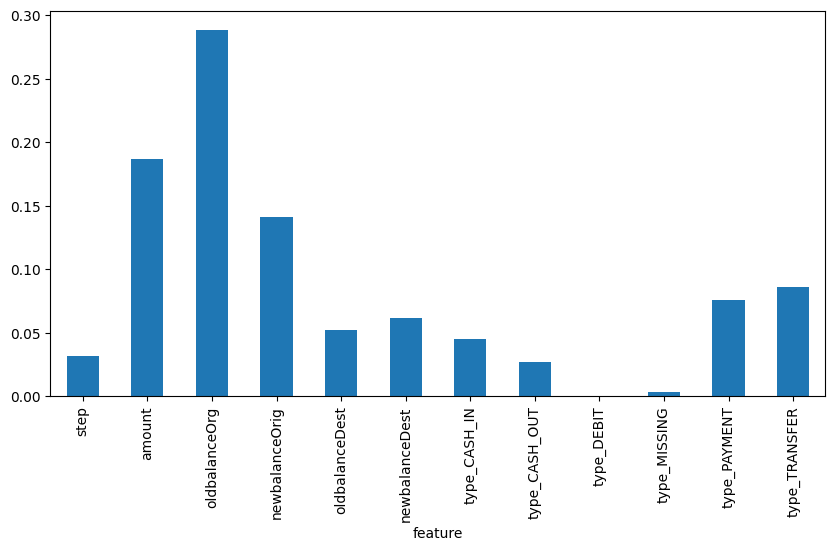

In [50]:
#Simple graph
feature_importance.plot(
    x="feature",
    y="importance",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

In [61]:
# Making Predictions
y_eval_pred = model.predict(X_eval)
y_live_pred = model.predict(X_live)

In [64]:
#Calculate metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

cm = confusion_matrix(y_eval, y_eval_pred)

print("Accuracy :", accuracy_score(y_eval, y_eval_pred))
print("Precision:", precision_score(y_eval, y_eval_pred))
print("Recall   :", recall_score(y_eval, y_eval_pred))
print("F1 Score :", f1_score(y_eval, y_eval_pred))
print("Confusion Metrix:", cm)
print(classification_report(y_eval, y_eval_pred))

Accuracy : 0.99978
Precision: 0.9970238095238095
Recall   : 0.6046931407942239
F1 Score : 0.7528089887640449
Confusion Metrix: [[999445      1]
 [   219    335]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    999446
           1       1.00      0.60      0.75       554

    accuracy                           1.00   1000000
   macro avg       1.00      0.80      0.88   1000000
weighted avg       1.00      1.00      1.00   1000000



In [ ]:
# Making Predictions
y_eval_pred = model.predict(X_eval)

In [65]:
#Check how many frauds were predicted
print("Total transactions:", len(y_eval_pred))
print("Predicted fraud:", y_eval_pred.sum())
print("Predicted non-fraud:", (y_eval_pred == 0).sum())

Total transactions: 1000000
Predicted fraud: 336
Predicted non-fraud: 999664


In [ ]:
# Compare actual vs predict for 10 transaction

In [66]:
comparison = pd.DataFrame({
    "Actual": y_eval.iloc[:10].values,
    "Predicted": y_eval_pred[:10]
})

print(comparison)

   Actual  Predicted
0       0          0
1       0          0
2       0          0
3       0          0
4       0          0
5       0          0
6       0          0
7       0          0
8       0          0
9       0          0


In [60]:
## With y_live data
y_live_pred = model.predict(X_live)

In [62]:
comparison_live = pd.DataFrame({
    "Actual": y_live.iloc[:10].values,
    "Predicted": y_live_pred[:10]
})

print(comparison_live)

   Actual  Predicted
0       0          0
1       0          0
2       0          0
3       0          0
4       0          0
5       0          0
6       0          0
7       0          0
8       0          0
9       0          0
